# Data analysis

In [1]:
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import os
from collections import defaultdict
from matplotlib.colors import LinearSegmentedColormap
from mpl_toolkits.axes_grid1 import make_axes_locatable

Load files and visualize stored variables

In [8]:
location = Path("../measurements/reorganized_files/experimental data/t=10s")

for file in sorted(location.glob(f'*.npz')):
    with np.load(file) as data:
        filename = file.name
        print(filename, data.files)

H_0_run_0.npz ['r0', 'cost', 'cost_e', 'E1', 'E1_e', 'E2', 'E2_e', 'trace', 'trace_e', 'energies', 'weights', 'calls', 'opt_parameters', 'density', 'error_D', 'qst_results']
H_0_run_1.npz ['r0', 'cost', 'cost_e', 'E1', 'E1_e', 'E2', 'E2_e', 'trace', 'trace_e', 'energies', 'weights', 'calls', 'opt_parameters', 'density', 'error_D', 'qst_results']
H_0_run_2.npz ['r0', 'cost', 'cost_e', 'E1', 'E1_e', 'E2', 'E2_e', 'trace', 'trace_e', 'energies', 'weights', 'calls', 'opt_parameters', 'density', 'error_D']
H_1_run_0.npz ['r0', 'cost', 'cost_e', 'E1', 'E1_e', 'E2', 'E2_e', 'trace', 'trace_e', 'energies', 'weights', 'calls', 'opt_parameters', 'density', 'error_D', 'qst_results']
H_1_run_1.npz ['r0', 'cost', 'cost_e', 'E1', 'E1_e', 'E2', 'E2_e', 'trace', 'trace_e', 'energies', 'weights', 'calls', 'opt_parameters', 'density', 'error_D', 'qst_results']
H_2_run_0.npz ['r0', 'cost', 'cost_e', 'E1', 'E1_e', 'E2', 'E2_e', 'trace', 'trace_e', 'energies', 'weights', 'calls', 'opt_parameters', 'density

Load every file in the folder and plot each run (cost and trace)

Loaded file ..\measurements\reorganized_files\experimental data\t=10s\H_0_run_0.npz


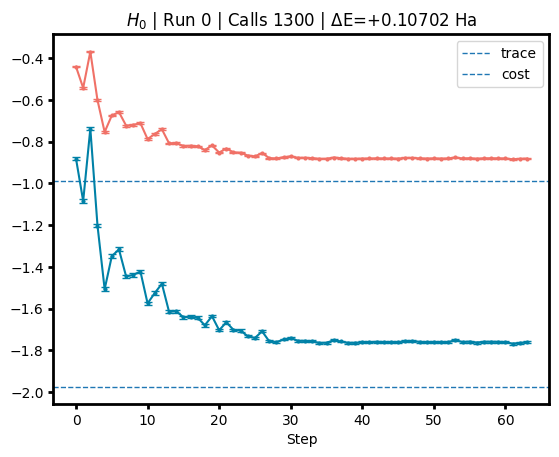

Loaded file ..\measurements\reorganized_files\experimental data\t=10s\H_0_run_1.npz


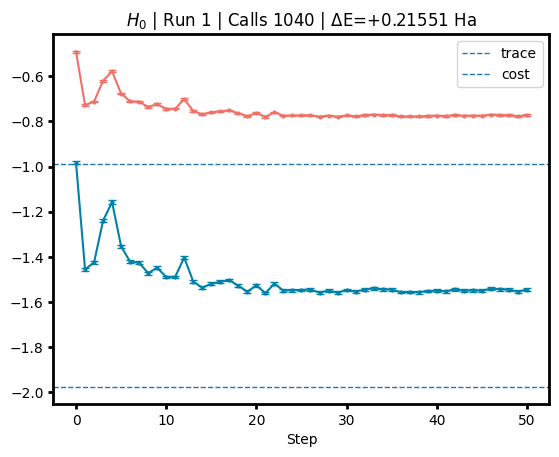

Loaded file ..\measurements\reorganized_files\experimental data\t=10s\H_0_run_2.npz


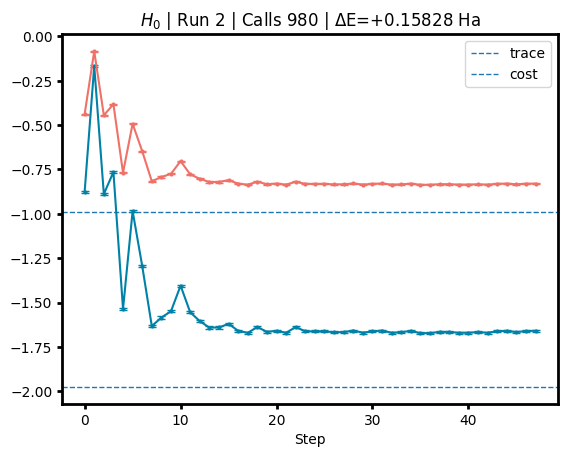

Loaded file ..\measurements\reorganized_files\experimental data\t=10s\H_1_run_0.npz


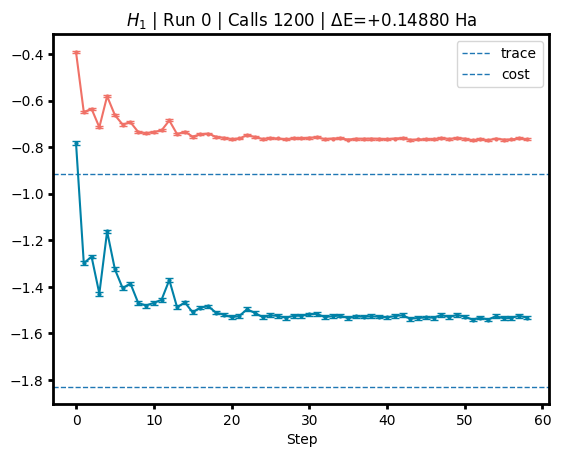

Loaded file ..\measurements\reorganized_files\experimental data\t=10s\H_1_run_1.npz


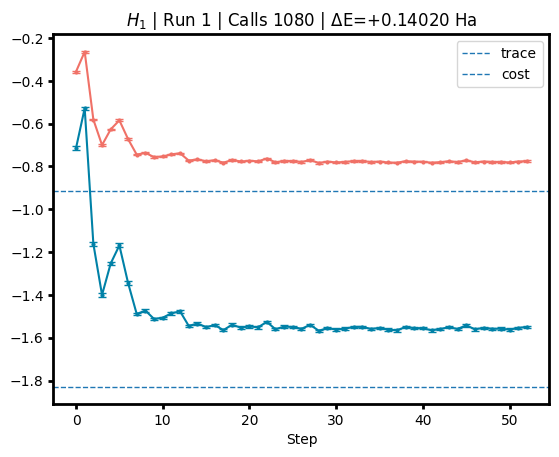

Loaded file ..\measurements\reorganized_files\experimental data\t=10s\H_2_run_0.npz


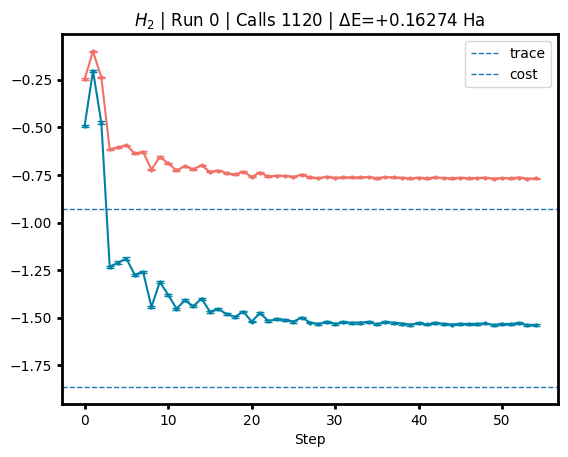

Loaded file ..\measurements\reorganized_files\experimental data\t=10s\H_2_run_1.npz


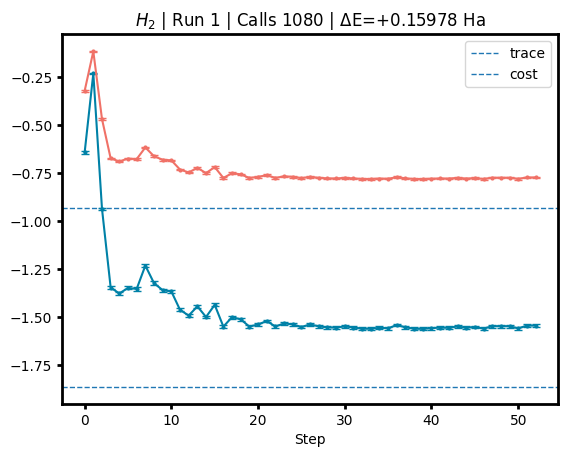

Loaded file ..\measurements\reorganized_files\experimental data\t=10s\H_3_run_0.npz


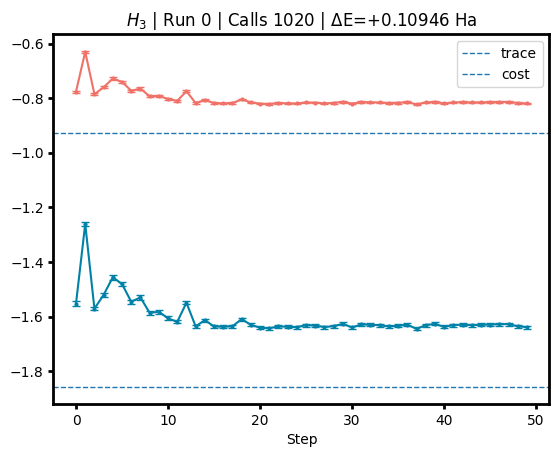

Loaded file ..\measurements\reorganized_files\experimental data\t=10s\H_3_run_1.npz


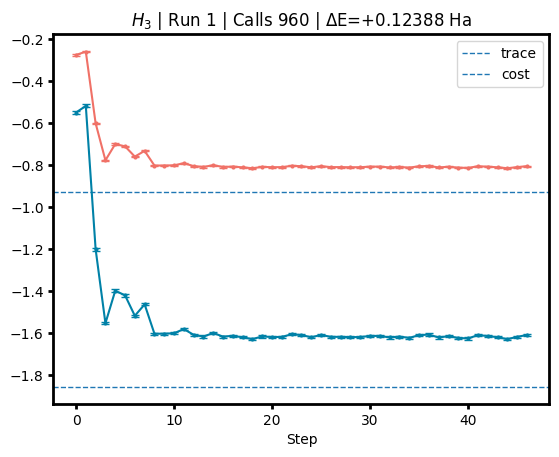

Loaded file ..\measurements\reorganized_files\experimental data\t=10s\H_4_run_0.npz


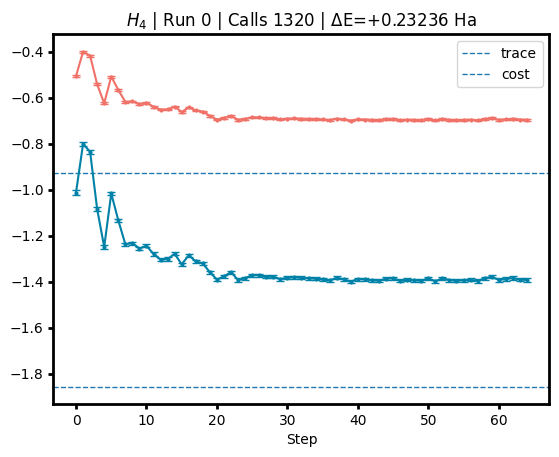

Loaded file ..\measurements\reorganized_files\experimental data\t=10s\H_4_run_1.npz


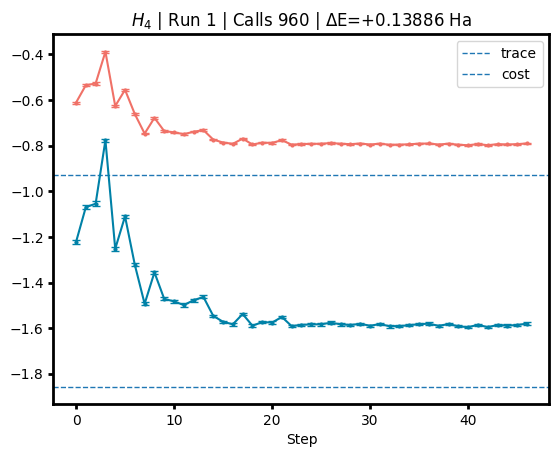

Loaded file ..\measurements\reorganized_files\experimental data\t=10s\H_5_run_0.npz


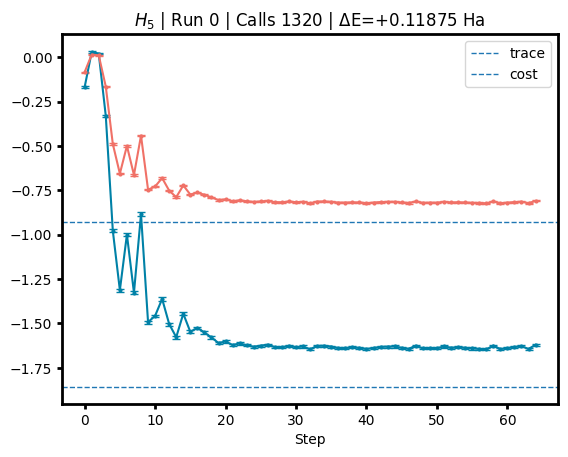

Loaded file ..\measurements\reorganized_files\experimental data\t=10s\H_5_run_1.npz


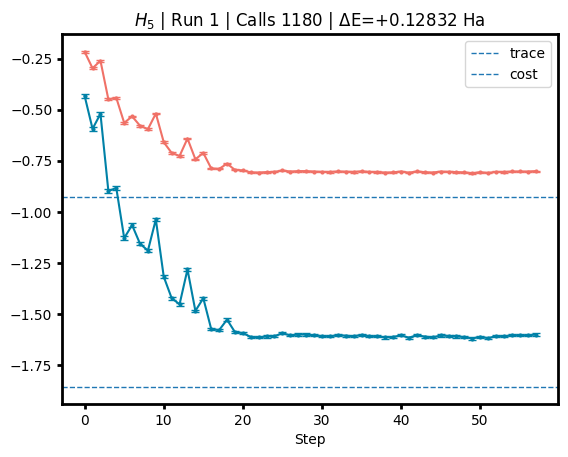

In [9]:
location = Path("../measurements/reorganized_files/experimental data/t=10s")

for file in sorted(location.glob(f'*.npz')):
    with np.load(file) as data:
        print(f'Loaded file {file}')
        filename = file.name
        H = filename[:3]
        run = filename[8]
        cost = np.array(data['cost'])
        cost_e = np.array(data['cost_e'])
        trace = np.array(data['trace'])
        trace_e = np.array(data['trace_e'])
        energies = np.array(data['energies'])
        calls = np.array(data['calls'])
        density = np.array(data['density']).real
        error_D = np.array(data['error_D'])
        weights = np.array(data['weights'])

        cost_true = weights @ energies[:2]
        trace_true = energies[0] + energies[1]
        fig, ax = plt.subplots()
        ax.spines[:].set_linewidth(2)
        ax.tick_params(width=2)
        xs = np.arange(len(cost))
    
        ax.set_xlabel("Step")
        ax.axhline(y=trace_true, linewidth=1, ls='--',  label='trace')
        ax.axhline(y=cost_true, linewidth=1, ls='--', label='cost')
        ax.errorbar(xs, trace, trace_e, marker='o', color = colors[0], markersize=2, capsize=3)
        ax.errorbar(xs, cost, cost_e, marker='o', color = colors[5], markersize=2, capsize=3)
        ax.set_title(f"${H}$ | Run {run} | Calls {calls} | ΔE={cost[-1]-cost_true:+.5f} Ha")
        ax.legend()

        plt.show()

Load every file in the folder and plot each density matrix

Loaded file ..\measurements\reorganized_files\experimental data\t=10s\H_0_run_0.npz
H_0
Loaded file ..\measurements\reorganized_files\experimental data\t=10s\H_0_run_1.npz
H_0
Loaded file ..\measurements\reorganized_files\experimental data\t=10s\H_0_run_2.npz
H_0
Loaded file ..\measurements\reorganized_files\experimental data\t=10s\H_1_run_0.npz
H_1
Loaded file ..\measurements\reorganized_files\experimental data\t=10s\H_1_run_1.npz
H_1
Loaded file ..\measurements\reorganized_files\experimental data\t=10s\H_2_run_0.npz
H_2
Loaded file ..\measurements\reorganized_files\experimental data\t=10s\H_2_run_1.npz
H_2
Loaded file ..\measurements\reorganized_files\experimental data\t=10s\H_3_run_0.npz
H_3
Loaded file ..\measurements\reorganized_files\experimental data\t=10s\H_3_run_1.npz
H_3
Loaded file ..\measurements\reorganized_files\experimental data\t=10s\H_4_run_0.npz
H_4
Loaded file ..\measurements\reorganized_files\experimental data\t=10s\H_4_run_1.npz
H_4
Loaded file ..\measurements\reor

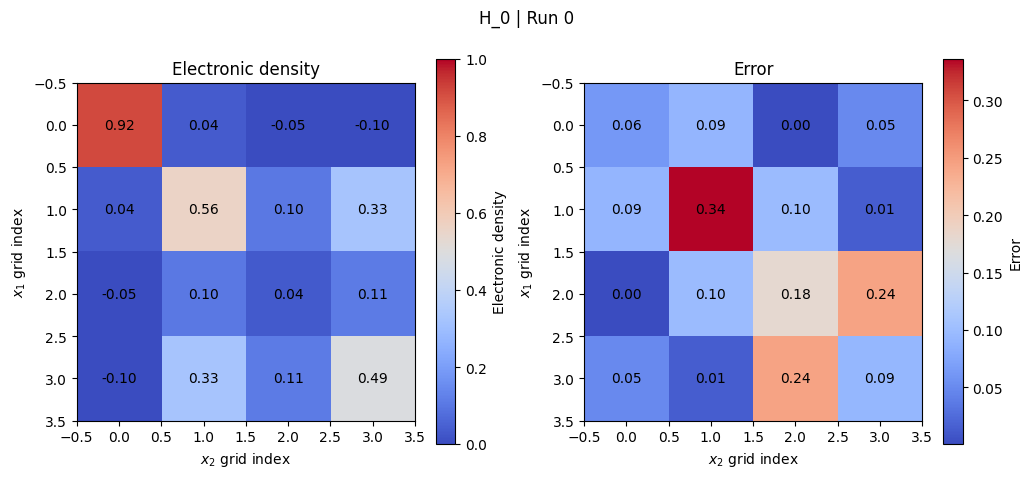

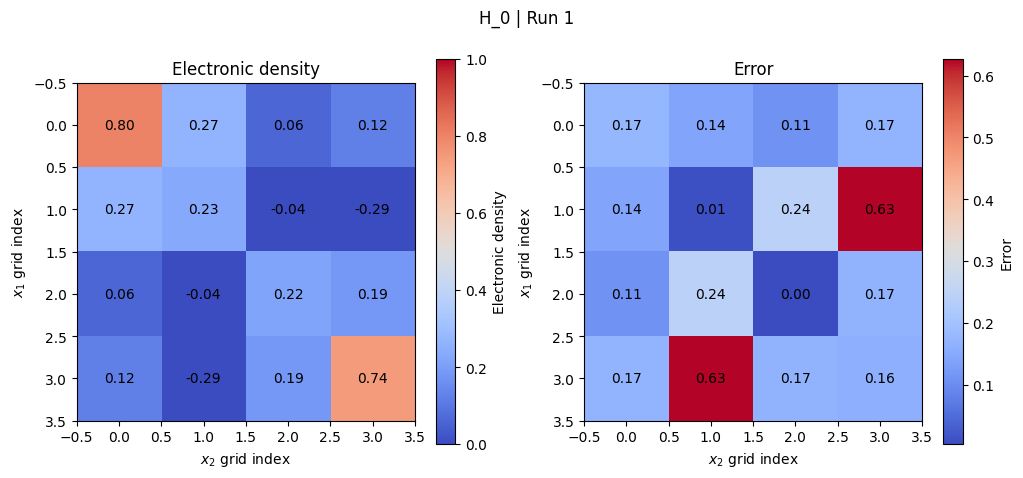

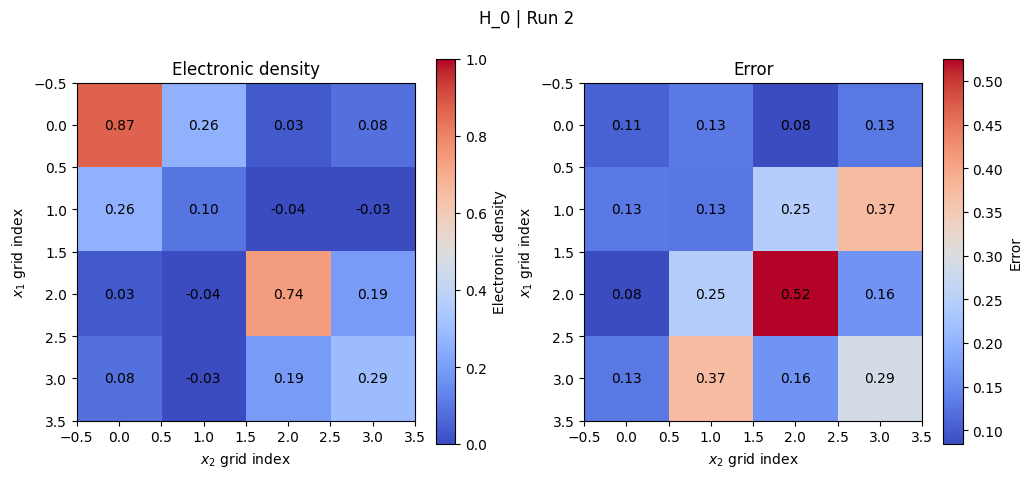

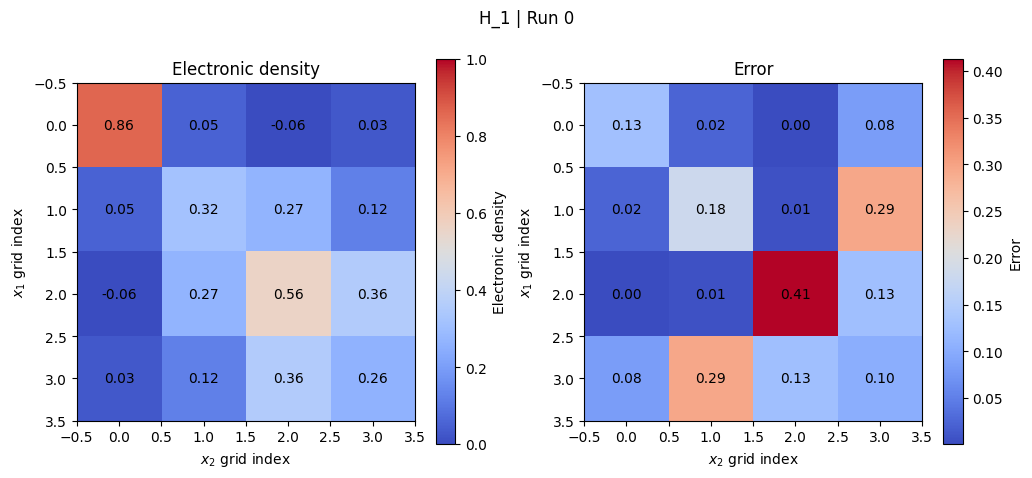

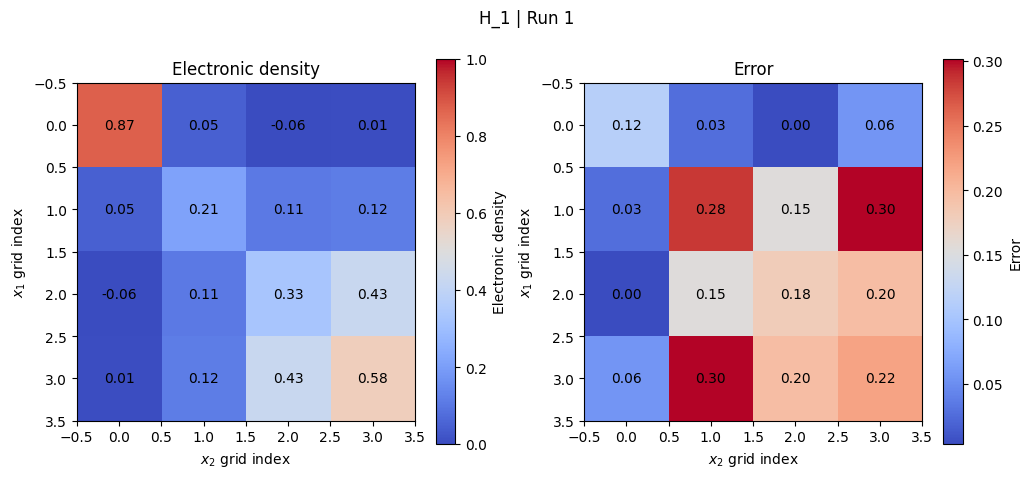

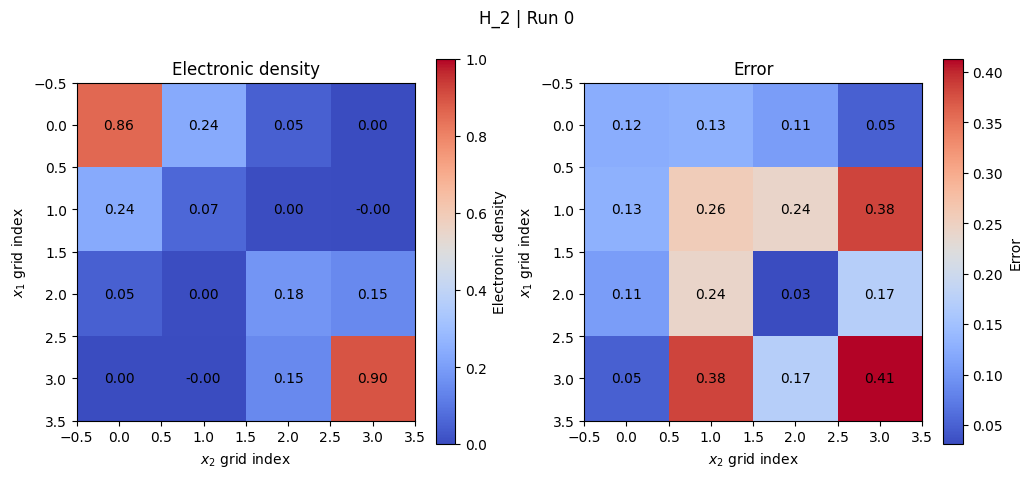

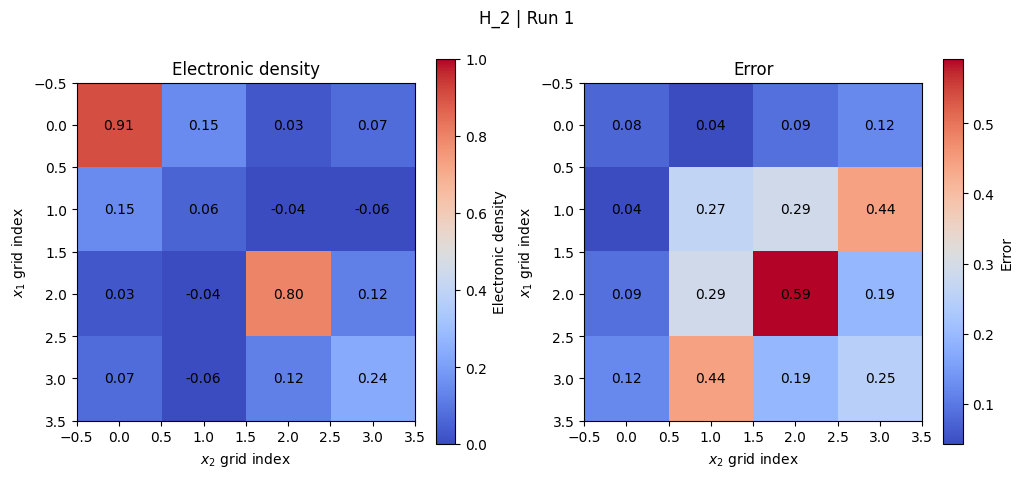

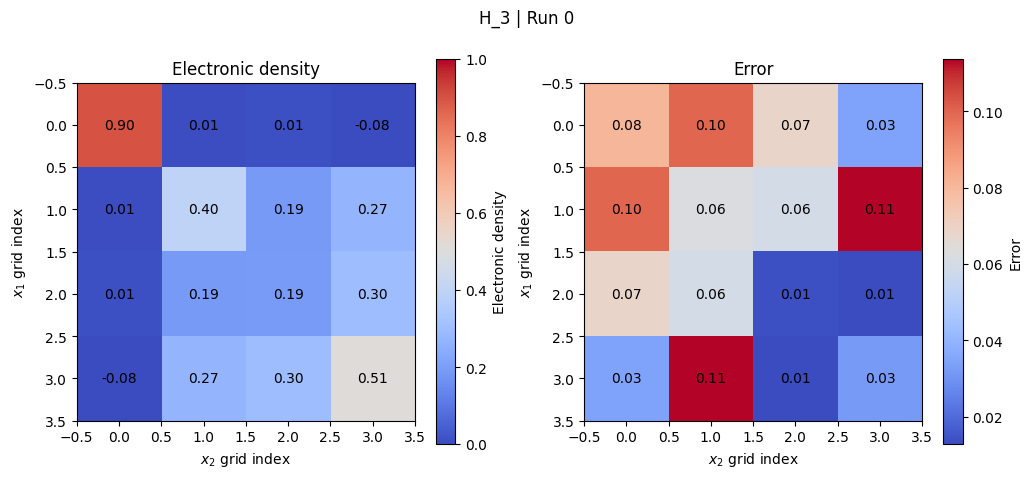

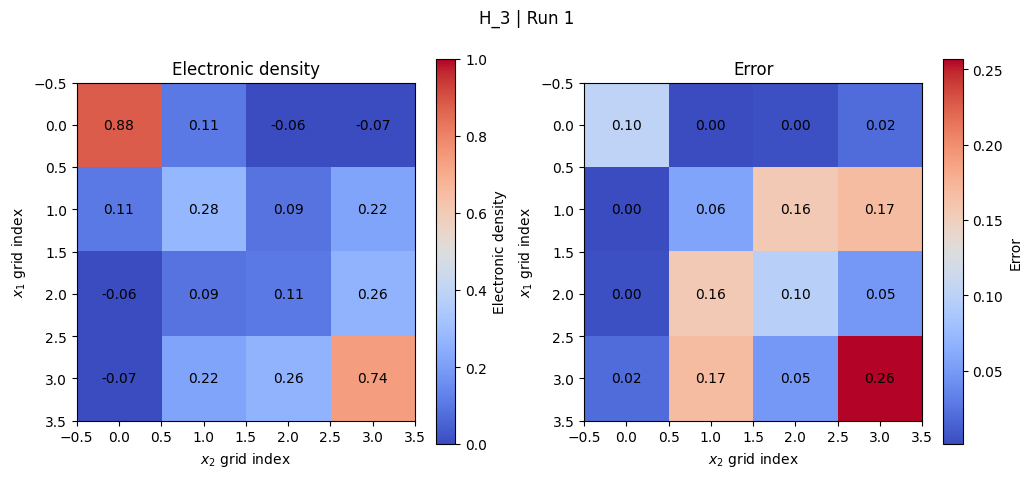

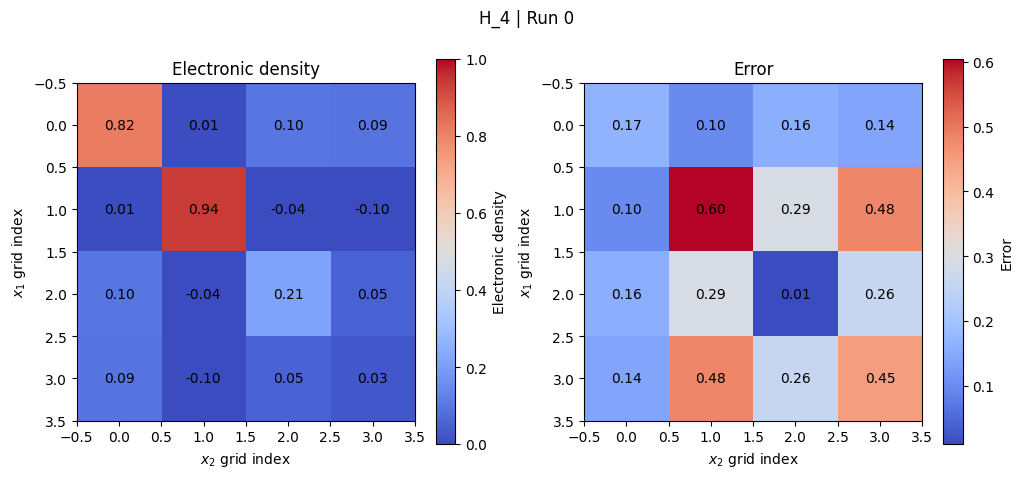

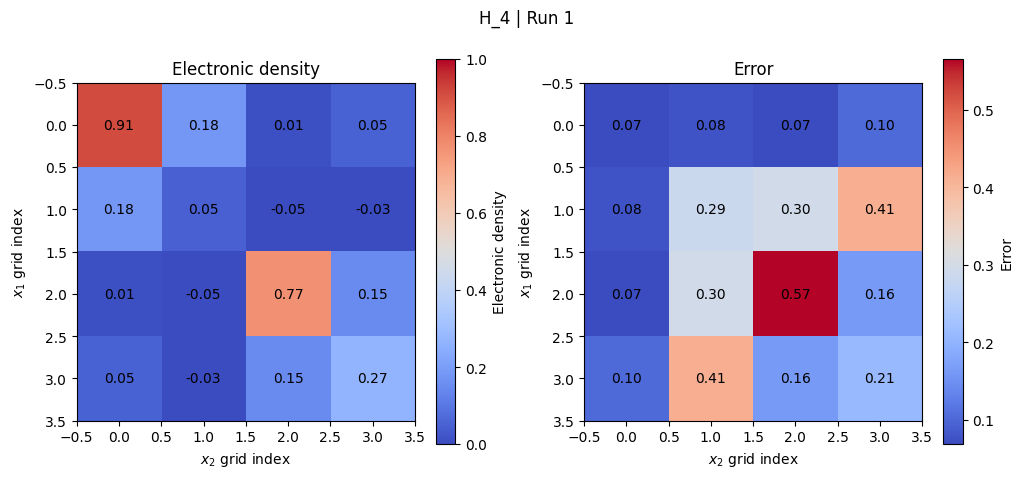

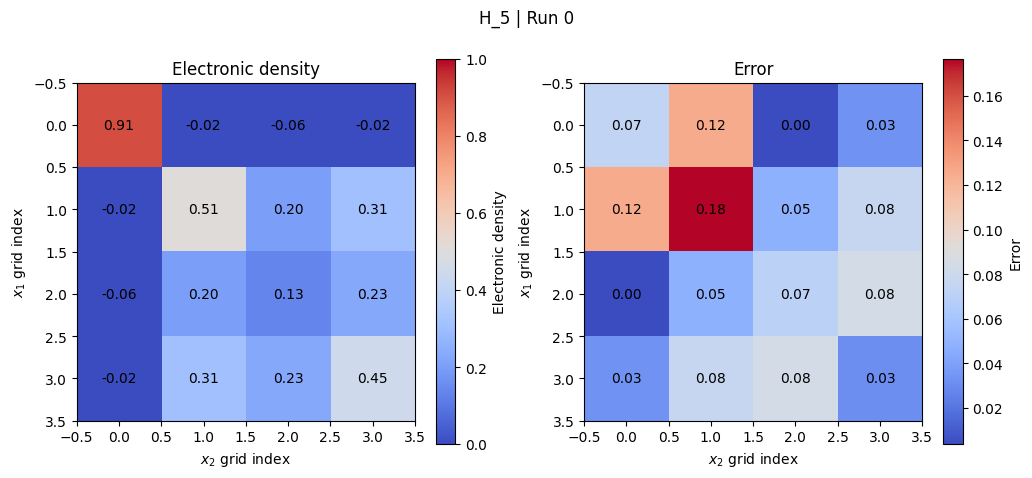

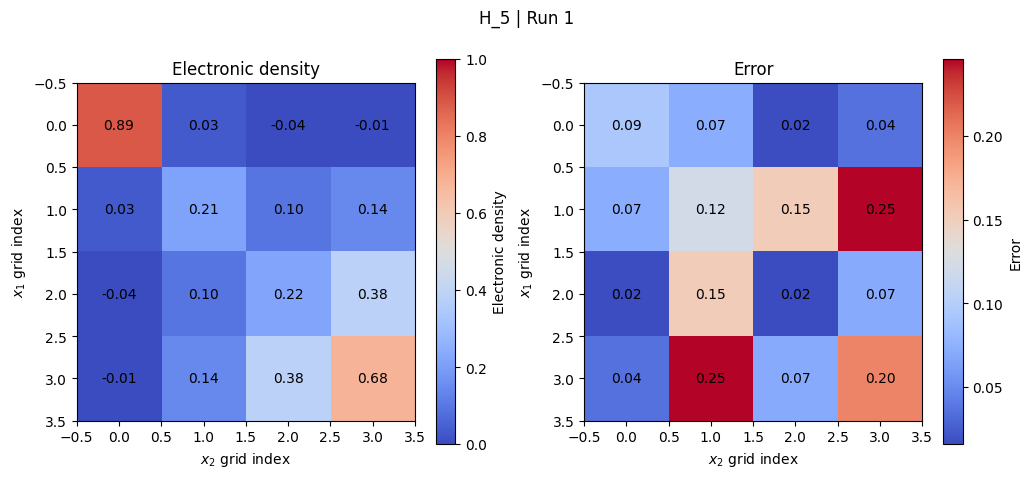

In [16]:
location = Path("../measurements/reorganized_files/experimental data/t=10s")

for file in sorted(location.glob(f'*.npz')):
    with np.load(file) as data:
        print(f'Loaded file {file}')
        filename = file.name
        H = filename[:3]
        run = filename[8]
        print(H)
        cost = np.array(data['cost'])
        cost_e = np.array(data['cost_e'])
        trace = np.array(data['trace'])
        trace_e = np.array(data['trace_e'])
        energies = np.array(data['energies'])
        calls = np.array(data['calls'])
        density = np.array(data['density']).real
        error_D = np.array(data['error_D'])
        weights = np.array(data['weights'])

        cost_true = weights @ energies[:2]
        trace_true = energies[0] + energies[0]
        fig, axs = plt.subplots(1,2, figsize=(12,5))
        im1 = axs[0].imshow(density, cmap='coolwarm', aspect='equal', interpolation='nearest', vmin=0, vmax=1)
        for k in range(density.shape[0]):
            for l in range(density.shape[0]):
                axs[0].text(l, k, f"{density[k, l]:.2f}", ha='center', va='center', color='black')
        axs[0].set_title(f'Electronic density')
        axs[0].set_xlabel(f"$x_2$ grid index")

        im2 = axs[1].imshow(error_D, cmap='coolwarm', aspect='equal', interpolation='nearest')
        for k in range(density.shape[0]):
            for l in range(density.shape[0]):
                axs[1].text(l, k, f"{error_D[k, l]:.2f}", ha='center', va='center', color='black')
        axs[1].set_title(f'Error')
        axs[1].set_xlabel(f"$x_2$ grid index")
    
        fig.colorbar(im1, ax=axs[0], label="Electronic density")
        fig.colorbar(im2, ax=axs[1], label="Error")
        
        axs[0].set_ylabel(f"$x_1$ grid index")
        axs[1].set_ylabel(f"$x_1$ grid index")
        plt.suptitle(f'{H} | Run {run}')

Quantum state tomography measurements: ['XX', 'YY', 'ZZ', 'YX', 'ZX', 'XY', 'ZY', 'XZ', 'YZ']

Each file has a qst_results dictionary with a list of 4 values, corresponding to the photon counts of the events 1010, 1001, 0110, 0101 for each Pauli operator. These can be used to reconstruct the density matrix. The MLE method has not been implemented yet.

In [21]:
for file in sorted(location.glob(f'*.npz')):
    with np.load(file, allow_pickle=True) as data:
        print(f'Loaded file {file}')
        filename = file.name
        H = filename[:3]
        run = filename[8]
        if 'qst_results' not in data:
            print(f"Skipping {filename}: no 'qst_results' key")
            continue
        
        qst_results = data['qst_results']
        print(f'Run {run} | {H}')
        print(qst_results)

Loaded file ..\measurements\reorganized_files\experimental data\t=10s\H_0_run_0.npz
Run 0 | H_0
{'II': array([28841.73736771,  1885.23469514,   207.08280239,   604.75704853]), 'XX': array([ 5264.93888948,  8360.88310995, 10739.51346295,  7437.29554934]), 'YY': array([ 8580.92484998,  5743.85872187,  6182.58441572, 10475.45344581]), 'ZZ': array([28584.28834543,  2030.74295048,   162.78701578,   609.17940355]), 'YX': array([7659.64033224, 6822.95644033, 8050.75921588, 8367.0956916 ]), 'ZX': array([15443.74981989, 15230.57212864,   580.27480456,   185.7389107 ]), 'XY': array([6590.48220254, 6737.98811604, 8513.65018593, 9440.6223719 ]), 'ZY': array([15051.19325286, 15759.49994733,   296.78177027,   590.38439473]), 'XZ': array([12771.38641508,   992.00518606, 15546.71370451,  1598.68133854]), 'YZ': array([13651.18121436,  1042.98618064, 14884.49169473,  1569.93603093])}
Loaded file ..\measurements\reorganized_files\experimental data\t=10s\H_0_run_1.npz
Run 1 | H_0
{'II': array([  330.85390